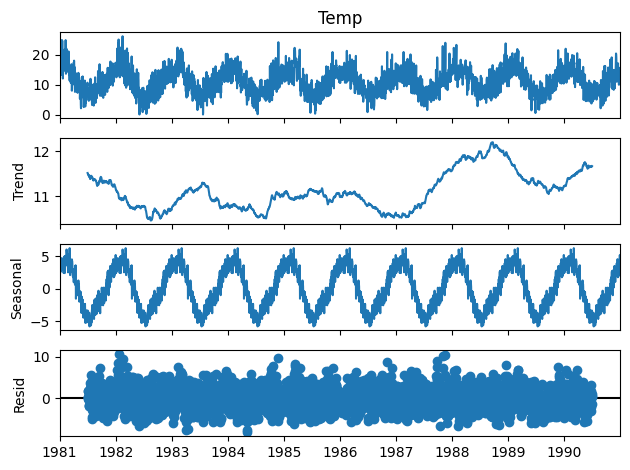

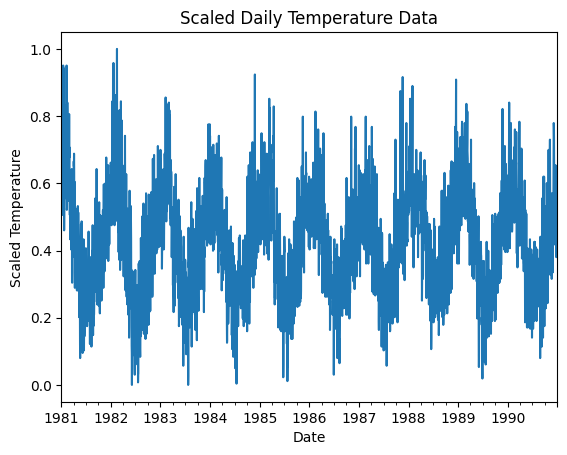

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/holtwinters/model.py:1065: ConvergenceWarning: Optimization failed to converge. Check mle_retvals.
  res = self._optimize_parameters(res, use_brute, method, minimize_kwargs)


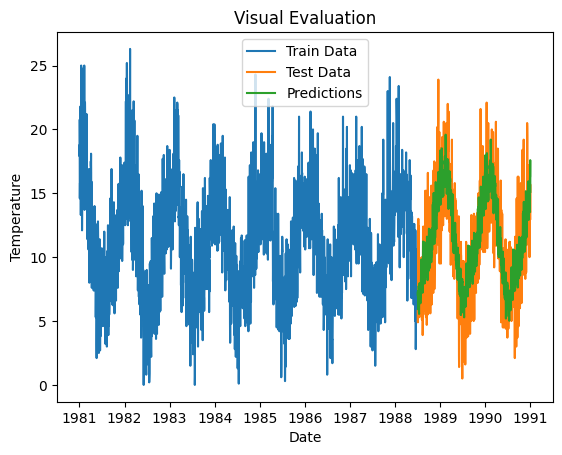

MAE: 2.181913846201386
MSE: 7.536785977994668
RMSE: 2.7453207422803385


/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/holtwinters/model.py:1065: ConvergenceWarning: Optimization failed to converge. Check mle_retvals.
  res = self._optimize_parameters(res, use_brute, method, minimize_kwargs)


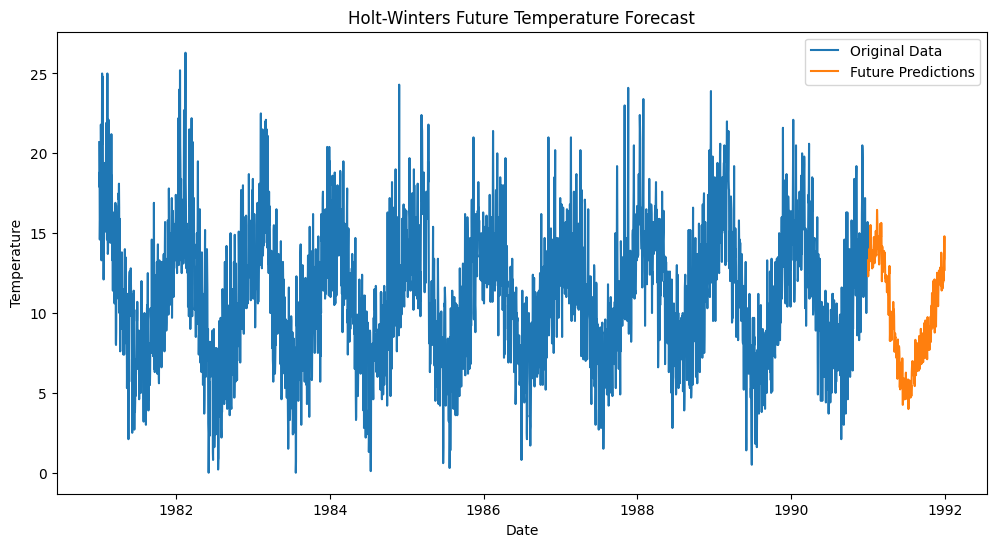

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from statsmodels.tsa.holtwinters import ExponentialSmoothing
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error
from statsmodels.tsa.seasonal import seasonal_decompose

# Step 1: Load the dataset, set daily frequency, and interpolate missing values
url = 'https://raw.githubusercontent.com/jbrownlee/Datasets/master/daily-min-temperatures.csv'

data = pd.read_csv(url, parse_dates=['Date'], index_col='Date')
data = data.asfreq('D').interpolate(method='linear')

data.head()

# Step 2: Explore and plot data
X = data['Temp']

# Step 3: Check for seasonality
decomposition = seasonal_decompose(X, model='additive', period=365)

decomposition.plot()
plt.show()

# Scale the data
scaler = MinMaxScaler()

scaled_data = pd.Series(
    scaler.fit_transform(X.values.reshape(-1, 1)).flatten(),
    index=X.index
)

# Plot scaled data
scaled_data.plot()
plt.title('Scaled Daily Temperature Data')
plt.xlabel('Date')
plt.ylabel('Scaled Temperature')
plt.show()

# Step 4: Split train and test data
split = int(len(X) * 0.75)

train_raw = X[:split]
test_raw = X[split:]

# Step 5: Scale the data
scaler = MinMaxScaler()

train_scaled = scaler.fit_transform(
    train_raw.values.reshape(-1, 1)
).flatten() + 1

test_scaled = scaler.transform(
    test_raw.values.reshape(-1, 1)
).flatten() + 1

train_data = pd.Series(train_scaled, index=train_raw.index)
test_data = pd.Series(test_scaled, index=test_raw.index)

# Step 6: Create and train Holt-Winters model
model_add = ExponentialSmoothing(
    train_data,
    trend='add',
    seasonal='mul',
    seasonal_periods=365
).fit()

# Step 7: Predict test data
test_predictions_add = model_add.forecast(steps=len(test_data))

# Convert predictions back to original temperature scale
predictions = scaler.inverse_transform(
    (test_predictions_add.values - 1).reshape(-1, 1)
).flatten()

actual = scaler.inverse_transform(
    (test_data.values - 1).reshape(-1, 1)
).flatten()

# Step 8: Visual evaluation
plt.plot(train_raw, label='Train Data')
plt.plot(test_raw, label='Test Data')
plt.plot(test_raw.index, predictions, label='Predictions')

plt.title('Visual Evaluation')
plt.xlabel('Date')
plt.ylabel('Temperature')
plt.legend()
plt.show()

# Step 9: Evaluate the model
mae = mean_absolute_error(actual, predictions)
mse = mean_squared_error(actual, predictions)
rmse = np.sqrt(mse)

print('MAE:', mae)
print('MSE:', mse)
print('RMSE:', rmse)

# Step 10: Create the final model using complete data
final_scaler = MinMaxScaler()

scaled_data = final_scaler.fit_transform(
    X.values.reshape(-1, 1)
).flatten() + 1

scaled_series = pd.Series(scaled_data, index=X.index)

final_model = ExponentialSmoothing(
    scaled_series,
    trend='add',
    seasonal='mul',
    seasonal_periods=365
).fit()

# Step 11: Predict future data for one year
final_predictions = final_model.forecast(steps=365)

future_values = final_scaler.inverse_transform(
    (final_predictions.values - 1).reshape(-1, 1)
).flatten()

future_dates = pd.date_range(
    start=X.index[-1] + pd.Timedelta(days=1),
    periods=365,
    freq='D'
)

future_series = pd.Series(future_values, index=future_dates)

# Step 12: Plot future predictions
plt.figure(figsize=(12, 6))

plt.plot(X, label='Original Data')
plt.plot(future_series, label='Future Predictions')

plt.title('Holt-Winters Future Temperature Forecast')
plt.xlabel('Date')
plt.ylabel('Temperature')
plt.legend()
plt.show()